In [458]:
# PART 1: LOAD AND INSPECT THE DATASET

# Import the necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("classification_escalation.csv")

# 1. Display dataset shape
print("Dataset Shape:")
print(df.shape)

# 2. Display the first 5 rows
print("\nFirst 5 Rows:")
display(df.head())

# 3. Display dataset information
print("\nDataset Information:")
df.info()

# 4. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 5. Check target prevalence
print("\nTarget Prevalence:")
print(df["escalated"].value_counts(normalize=True).rename("proportion"))

Dataset Shape:
(900, 6)

First 5 Rows:


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    str    
 3   channel                 900 non-null    str    
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 42.3 KB

Missing Values:
complexity_score           0
team_experience_years     31
priority                  18
channel                    0
customer_tenure_months    22
escalated                  0
dtype: int64

Target Prevalence:
escalated
0    0.793333
1    0.206667
Name: proportion, dtype: float64


In [459]:

# PART 2: SPLIT THE DATA INTO TRAIN AND TEST

# Separate the features from the target
X = df.drop("escalated", axis=1)
y = df["escalated"]

# Split the dataset
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Display the sizes
print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training set shape: (675, 5)
Testing set shape: (225, 5)

Training target distribution:
escalated
0    0.792593
1    0.207407
Name: proportion, dtype: float64

Testing target distribution:
escalated
0    0.795556
1    0.204444
Name: proportion, dtype: float64


In [460]:
# PART 3: PREPROCESSING

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Identify numeric and categorical columns
numeric_features = [
    "complexity_score",
    "team_experience_years",
    "customer_tenure_months"
]

categorical_features = [
    "priority",
    "channel"
]

# Numeric preprocessing pipeline
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing pipeline
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine numeric and categorical preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipelines created successfully.")

Preprocessing pipelines created successfully.


In [461]:
# PART 4: MAJORITY-CLASS BASELINE

from sklearn.dummy import DummyClassifier

# Create the baseline model
baseline_model = DummyClassifier(strategy="most_frequent")

# Train the baseline model
baseline_model.fit(X_train, y_train)

# Make predictions
baseline_predictions = baseline_model.predict(X_test)

print("Baseline model trained successfully.")

Baseline model trained successfully.


In [462]:
# PART 4.2: EVALUATE BASELINE

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Calculate evaluation metrics
baseline_accuracy = accuracy_score(y_test, baseline_predictions)

baseline_precision = precision_score(
    y_test, baseline_predictions, zero_division=0
)

baseline_recall = recall_score(
    y_test, baseline_predictions, zero_division=0
)

baseline_f1 = f1_score(
    y_test, baseline_predictions, zero_division=0
)

# Display results
print("Baseline Model Results")
print("--------------------")
print("Accuracy:", baseline_accuracy)
print("Precision:", baseline_precision)
print("Recall:", baseline_recall)
print("F1 Score:", baseline_f1)

Baseline Model Results
--------------------
Accuracy: 0.7955555555555556
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


In [463]:
# PART 5: LOGISTIC REGRESSION

from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression pipeline
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
logistic_model.fit(X_train, y_train)

# Make predictions
logistic_predictions = logistic_model.predict(X_test)

# Get predicted probabilities for class 1
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [464]:
# PART 6: LINEAR DISCRIMINANT ANALYSIS

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Create the LDA pipeline
lda_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LinearDiscriminantAnalysis())
])

# Train the model
lda_model.fit(X_train, y_train)

# Make predictions
lda_predictions = lda_model.predict(X_test)

# Get probabilities for class 1
lda_probabilities = lda_model.predict_proba(X_test)[:, 1]

print("LDA trained successfully.")

LDA trained successfully.


In [465]:
# PART 7: K-NEAREST NEIGHBORS (K=15)

from sklearn.neighbors import KNeighborsClassifier

# Create the k-NN pipeline
knn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=15))
])

# Train the model
knn_model.fit(X_train, y_train)

# Make predictions
knn_predictions = knn_model.predict(X_test)

# Get probabilities for class 1
knn_probabilities = knn_model.predict_proba(X_test)[:, 1]

print("k-NN trained successfully.")

k-NN trained successfully.


In [466]:
# PART 8: MODEL COMPARISON

from sklearn.metrics import roc_auc_score

# Create a function to calculate metrics
def evaluate_model(y_true, predictions, probabilities=None):

    accuracy = accuracy_score(y_true, predictions)

    precision = precision_score(
        y_true, predictions, zero_division=0
    )

    recall = recall_score(
        y_true, predictions, zero_division=0
    )

    f1 = f1_score(
        y_true, predictions, zero_division=0
    )

    # Calculate ROC-AUC if probabilities are available
    if probabilities is not None:
        roc_auc = roc_auc_score(y_true, probabilities)
    else:
        roc_auc = np.nan

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": roc_auc
    }


# Evaluate the baseline
baseline_results = evaluate_model(
    y_test, baseline_predictions
)

# Evaluate Logistic Regression
logistic_results = evaluate_model(
    y_test, logistic_predictions, logistic_probabilities
)

# Evaluate LDA
lda_results = evaluate_model(
    y_test, lda_predictions, lda_probabilities
)

# Evaluate k-NN
knn_results = evaluate_model(
    y_test, knn_predictions, knn_probabilities
)


# Combine results
comparison_df = pd.DataFrame(
    {
        "Majority Baseline": baseline_results,
        "Logistic Regression": logistic_results,
        "LDA": lda_results,
        "k-NN (k=15)": knn_results
    }
).T


# Display results
print("Model Comparison:")
display(comparison_df.round(4))

Model Comparison:


,Accuracy,Precision,Recall,F1,ROC-AUC
Majority Baseline,0.7956,0.00,0.0000,0.0000,NaN
Logistic Regression,0.8222,0.75,0.1957,0.3103,0.8111
LDA,0.8222,0.75,0.1957,0.3103,0.8090
k-NN (k=15),0.7956,0.50,0.0870,0.1481,0.7046


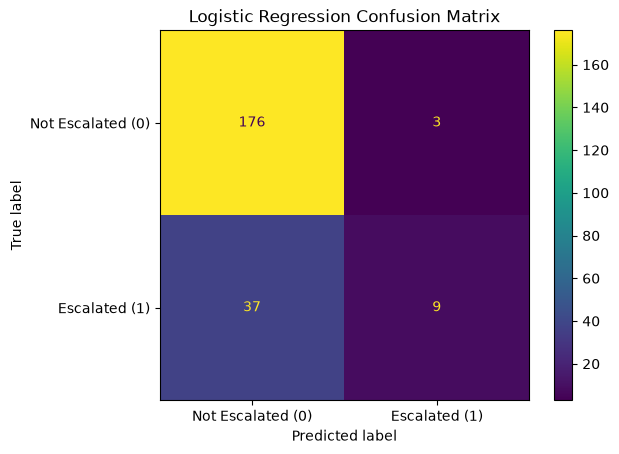

In [467]:
# PART 9: CONFUSION MATRIX

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate confusion matrix
cm = confusion_matrix(y_test, logistic_predictions)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Escalated (0)", "Escalated (1)"]
)

disp.plot()

plt.title("Logistic Regression Confusion Matrix")
plt.show()

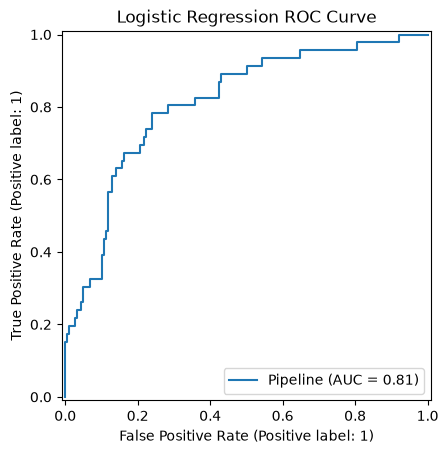

In [468]:
# PART 9.2: ROC CURVE

from sklearn.metrics import RocCurveDisplay

# Plot ROC curve for Logistic Regression
RocCurveDisplay.from_estimator(
    logistic_model,
    X_test,
    y_test
)

plt.title("Logistic Regression ROC Curve")
plt.show()

In [469]:
# PART 10: EVALUATE DIFFERENT THRESHOLDS

from sklearn.metrics import confusion_matrix

# Define the thresholds we want to test
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

# Create an empty list to store results
threshold_results = []

# Evaluate each threshold
for threshold in thresholds:

    # Convert probabilities into binary predictions
    predictions = (logistic_probabilities >= threshold).astype(int)

    # Calculate precision, recall, and F1 score
    precision = precision_score(y_test, predictions, zero_division=0)
    recall = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)

    # Calculate confusion matrix values
    tn, fp, fn, tp = confusion_matrix(y_test, predictions).ravel()

    # Store the results
    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "FP": fp,
        "FN": fn
    })

# Convert results into a DataFrame
threshold_df = pd.DataFrame(threshold_results)

# Display the results
print("Threshold Evaluation Results:")
display(threshold_df.round(4))

Threshold Evaluation Results:


,Threshold,Precision,Recall,F1,FP,FN
0,0.2,0.4286,0.7826,0.5538,48,10
1,0.3,0.5490,0.6087,0.5773,23,18
2,0.4,0.5714,0.2609,0.3582,9,34
3,0.5,0.7500,0.1957,0.3103,3,37
4,0.6,1.0000,0.0652,0.1224,0,43
5,0.7,0.0000,0.0000,0.0000,0,46


In [470]:
# PART 11: COST-SENSITIVE THRESHOLD ANALYSIS

# Calculate the cost for each threshold
threshold_df["Cost"] = 5 * threshold_df["FN"] + threshold_df["FP"]

# Display the threshold results with cost
print("Threshold Results with Cost:")
display(threshold_df.round(4))

# Find the threshold with the minimum cost
best_threshold_row = threshold_df.loc[threshold_df["Cost"].idxmin()]

# Display the best threshold
print("\nThreshold with Minimum Cost:")
print(best_threshold_row)

Threshold Results with Cost:


,Threshold,Precision,Recall,F1,FP,FN,Cost
0,0.2,0.4286,0.7826,0.5538,48,10,98
1,0.3,0.5490,0.6087,0.5773,23,18,113
2,0.4,0.5714,0.2609,0.3582,9,34,179
3,0.5,0.7500,0.1957,0.3103,3,37,188
4,0.6,1.0000,0.0652,0.1224,0,43,215
5,0.7,0.0000,0.0000,0.0000,0,46,230



Threshold with Minimum Cost:
Threshold     0.200000
Precision     0.428571
Recall        0.782609
F1            0.553846
FP           48.000000
FN           10.000000
Cost         98.000000
Name: 0, dtype: float64


In [471]:
# PART 12: CROSS-VALIDATION AND k-NN TUNING

from sklearn.model_selection import StratifiedKFold, GridSearchCV

# Create a k-NN pipeline
knn_tuning_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier())
])

# Define the values of k to test
param_grid = {
    "classifier__n_neighbors": [5, 9, 15, 21, 31]
}

# Create 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Create GridSearchCV
grid_search = GridSearchCV(
    estimator=knn_tuning_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

# Train and tune the model
grid_search.fit(X_train, y_train)

# Display the best results
print("Best k:", grid_search.best_params_)
print("Best Cross-Validation F1:", grid_search.best_score_)

Best k: {'classifier__n_neighbors': 5}
Best Cross-Validation F1: 0.24329611908559276


In [472]:
# Display the cross-validation results

cv_results_df = pd.DataFrame(grid_search.cv_results_)

cv_results_df = cv_results_df[
    ["param_classifier__n_neighbors",
     "mean_test_score",
     "std_test_score"]
]

cv_results_df = cv_results_df.rename(columns={
    "param_classifier__n_neighbors": "k",
    "mean_test_score": "Mean F1",
    "std_test_score": "Standard Deviation"
})

display(cv_results_df.round(4))

,k,Mean F1,Standard Deviation
0,5,0.2433,0.0946
1,9,0.1976,0.0652
2,15,0.1596,0.0655
3,21,0.1458,0.0564
4,31,0.1122,0.0397


In [473]:
# EVALUATE THE TUNED k-NN MODEL ON TEST DATA

# Get the best model found by GridSearchCV
best_knn_model = grid_search.best_estimator_

# Make predictions
best_knn_predictions = best_knn_model.predict(X_test)

# Get predicted probabilities for class 1
best_knn_probabilities = best_knn_model.predict_proba(X_test)[:, 1]

# Evaluate the tuned model
best_knn_results = evaluate_model(
    y_test,
    best_knn_predictions,
    best_knn_probabilities
)

# Display results
print("Tuned k-NN Test Results:")

display(pd.DataFrame(
    [best_knn_results],
    index=["Tuned k-NN"]
).round(4))

Tuned k-NN Test Results:


,Accuracy,Precision,Recall,F1,ROC-AUC
Tuned k-NN,0.7911,0.4615,0.1304,0.2034,0.6307


q1:-Why is accuracy alone potentially misleading?

Accuracy alone can be misleading because the dataset contains more non-escalated tickets than escalated tickets. A model can achieve high accuracy by predicting mostly or entirely the majority class while failing to identify escalated tickets. Therefore, precision, recall, F1-score, and ROC-AUC are also important for evaluating classification performance.

q2:- Which classifier has the strongest recall? Which has the strongest precision/F1?

Logistic Regression and Linear Discriminant Analysis (LDA) tied for the highest precision, recall, and F1-score. Both models achieved a precision of 0.75, recall of 0.1957, and F1-score of 0.3103. However, Logistic Regression had a slightly higher ROC-AUC of 0.8111 compared to LDA's 0.8090. The k-NN model with k=15 performed worse, with a recall of 0.0870 and an F1-score of 0.1481. The Majority Baseline achieved zero precision, recall, and F1-score because it predicted only the majority class.

q3:- What changes when the threshold is lowered?

When the classification threshold is lowered, the model becomes more likely to predict the positive class (escalated). This generally increases recall because more actual escalated tickets are identified, but it can also increase false positives and reduce precision. In my experiment, lowering the threshold from 0.50 to 0.20 increased recall from 0.1957 to 0.7826 and increased false positives from 3 to 48, while reducing false negatives from 37 to 10.

q4:- Which threshold minimizes 5×FN + FP on the test set, and why might this estimate be optimistic if used repeatedly for tuning?

The threshold of 0.20 minimizes the cost among the six tested thresholds, with a total cost of 98. It produced 48 false positives and 10 false negatives. Since missing an escalated ticket costs five times more than a false positive, the lower threshold reduces the overall cost.
However, this estimate may be optimistic because the same test set was used to compare and select thresholds. Repeatedly using the test set for tuning can lead to overfitting to the test data. A separate validation set should be used for threshold selection, while the test set should be reserved for final evaluation.

q5:- Explain prior, likelihood, posterior, and evidence using the ticket scenario

- Prior:- The probability that a ticket is escalated before considering its specific features. In this dataset, the prior probability of escalation is approximately 20.67%.

- Likelihood:- The probability of observing the ticket's features, such as complexity, priority, and customer tenure, given that it is escalated.

- Posterior:- The probability that a ticket is escalated after considering its observed features.

- Evidence:- The overall probability of observing the ticket's features, considering both escalated and non-escalated cases.

Bayes' theorem combines these values to calculate the posterior probability.

q6:- With posterior P(escalated|x)=0.30, false-positive cost 1 and false-negative cost 5, compare the expected cost of escalating and not escalating. Derive the cost-sensitive threshold.


Given a posterior probability of 0.30, the cost of a false positive is 1 and the cost of a false negative is 5.\
**Expected cost of escalating the ticket:** => 
           Expected cost = 1(1-0.30) = 0.70 \
**Expected cost of not escalating the ticket:** => 
           Expected cost = 5(0.30) = 1.50 \
Since the expected cost of escalating (0.70) is lower than the expected cost of not escalating (1.50), we should **escalate the ticket**.

The decision threshold can be derived as follows:\
1(1-p) < 5p \
1 - p < 5p\
1 < 6p\
p > 1/6\
p > 0.1667

Therefore, the decision threshold is approximately **0.1667 (16.67%)**. Since the posterior probability of 0.30 is greater than this threshold, the ticket should be escalated.

q7:- Which model would you recommend for deployment, and what further checks are required?


Based on the evaluation results, I recommend Logistic Regression as the preferred model among the classifiers tested. It achieved a ROC-AUC of 0.8111 and tied with LDA for precision (0.75), recall (0.1957), and F1-score (0.3103). Although the model performed well at the default threshold of 0.50 in terms of precision, it missed many escalated tickets. Therefore, lowering the threshold to 0.20 is a better choice under the given cost assumptions.

At threshold 0.20, the model achieved a recall of 0.7826, meaning it detected approximately 78.26% of the actual escalated tickets. It produced 10 false negatives and 48 false positives. Using the cost function of 5 for each false negative and 1 for each false positive, this threshold resulted in the lowest total cost of 98 among the tested thresholds.

Before using this model in a real-world environment, several further checks are necessary. First, the model should be tested on real support ticket data to determine whether its performance generalizes beyond the synthetic dataset. Second, its predictions should be checked for potential bias to ensure fair treatment of customers. Third, the model's performance should be monitored regularly because ticket patterns may change over time. Human oversight should also be maintained so that staff can review the model's predictions. Finally, the assumed error costs and selected threshold should be reassessed to ensure they reflect actual business needs.

Overall, Logistic Regression with a threshold of 0.20 is the preferred candidate for this experiment because it reduces the cost of missed escalations under the assumed cost function. However, further validation is needed before real-world deployment.